In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path
from PIL import Image

In [3]:
DATA_DIR = Path("../data/Laliga teams")

In [4]:
DATA_DIR = Path("../data/laliga teams").resolve()

team_dirs = sorted(
    path for path in DATA_DIR.iterdir()
    if path.is_dir()
)

for team_dir in team_dirs:
    images = list(team_dir.glob("*.jpg"))
    print(f"{team_dir.name}: {len(images)} images")

print("\nTotal teams:", len(team_dirs))

Athletic Bilbao: 100 images
Atletico Madrid: 100 images
Barcelona: 100 images
Celta Vigo: 100 images
Deportivo Alaves: 100 images
Espanyol: 100 images
Getafe: 100 images
Girona: 100 images
Las Palmas: 100 images
Leganes: 100 images
Mallorca: 100 images
Osasuna: 100 images
Rayo Vallecano: 100 images
Real Betis: 100 images
Real Madrid: 100 images
Real Sociedad: 100 images
Real Valladolid: 100 images
Sevilla: 100 images
Valencia: 100 images
Villarreal: 100 images

Total teams: 20


In [5]:
X = []
y = []

IMAGE_SIZE = (224, 224)

for team_dir in team_dirs:

    team_name = team_dir.name

    image_paths = sorted([
        *team_dir.glob("*.jpg"),
        *team_dir.glob("*.jpeg"),
        *team_dir.glob("*.JPG"),
        *team_dir.glob("*.JPEG")
    ])

    for image_path in image_paths:
        try:
            with Image.open(image_path) as image:
                image = image.convert("RGB")
                image = image.resize(IMAGE_SIZE)

                X.append(np.array(image))
                y.append(team_name)

        except Exception as error:
            print(f"Could not load {image_path}: {error}")

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of classes:", len(np.unique(y)))

X shape: (4000, 224, 224, 3)
y shape: (4000,)
Number of classes: 20


In [6]:
class_counts = pd.Series(y).value_counts().sort_index()

print(class_counts)
print("\nMinimum images per class:", class_counts.min())
print("Maximum images per class:", class_counts.max())
print("Total images:", class_counts.sum())

Athletic Bilbao     200
Atletico Madrid     200
Barcelona           200
Celta Vigo          200
Deportivo Alaves    200
Espanyol            200
Getafe              200
Girona              200
Las Palmas          200
Leganes             200
Mallorca            200
Osasuna             200
Rayo Vallecano      200
Real Betis          200
Real Madrid         200
Real Sociedad       200
Real Valladolid     200
Sevilla             200
Valencia            200
Villarreal          200
Name: count, dtype: int64

Minimum images per class: 200
Maximum images per class: 200
Total images: 4000


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [8]:
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Rescaling,
    Conv2D,
    MaxPooling2D,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)

In [9]:
model = Sequential([
    Input(shape=(224, 224, 3)),

    Rescaling(1./255),


    Conv2D(32, kernel_size=(3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),


    Conv2D(64, kernel_size=(3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),


    Conv2D(128, kernel_size=(3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),


    GlobalAveragePooling2D(),
    Dense(128, activation="relu"),
    Dropout(0.4),

    Dense(20, activation="softmax")
])

In [10]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)                │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 20)                  │           2,580 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 112,340 (438.83 KB)

 Trainable params: 112,340 (438.83 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
from tensorflow.keras.callbacks import EarlyStopping

In [13]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [14]:
print("X_train dtype:", X_train.dtype)
print("y_train dtype:", y_train.dtype)

print("y_train örnekleri:", y_train[:10])
print("y_val örnekleri:", y_val[:10])

X_train dtype: uint8
y_train dtype: <U16
y_train örnekleri: ['Real Madrid' 'Getafe' 'Osasuna' 'Deportivo Alaves' 'Real Valladolid'
 'Osasuna' 'Sevilla' 'Las Palmas' 'Mallorca' 'Valencia']
y_val örnekleri: ['Villarreal' 'Getafe' 'Celta Vigo' 'Deportivo Alaves' 'Osasuna'
 'Rayo Vallecano' 'Girona' 'Las Palmas' 'Real Sociedad' 'Sevilla']


In [15]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(y_train)
y_val = label_encoder.transform(y_val)
y_test = label_encoder.transform(y_test)

print("Number of classes:", len(label_encoder.classes_))
print("Classes:", label_encoder.classes_)
print("Encoded labels:", y_train[:10])

Number of classes: 20
Classes: ['Athletic Bilbao' 'Atletico Madrid' 'Barcelona' 'Celta Vigo'
 'Deportivo Alaves' 'Espanyol' 'Getafe' 'Girona' 'Las Palmas' 'Leganes'
 'Mallorca' 'Osasuna' 'Rayo Vallecano' 'Real Betis' 'Real Madrid'
 'Real Sociedad' 'Real Valladolid' 'Sevilla' 'Valencia' 'Villarreal']
Encoded labels: [14  6 11  4 16 11 17  8 10 18]


In [16]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 169s 2s/step - accuracy: 0.1582 - loss: 2.6257 - val_accuracy: 0.5500 - val_loss: 1.8530
Epoch 2/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 169s 2s/step - accuracy: 0.5146 - loss: 1.4017 - val_accuracy: 0.8650 - val_loss: 0.4980
Epoch 3/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 188s 2s/step - accuracy: 0.8161 - loss: 0.5447 - val_accuracy: 1.0000 - val_loss: 0.1227
Epoch 4/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 157s 2s/step - accuracy: 0.9232 - loss: 0.2555 - val_accuracy: 1.0000 - val_loss: 0.0429
Epoch 5/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 808s 9s/step - accuracy: 0.9596 - loss: 0.1418 - val_accuracy: 1.0000 - val_loss: 0.0084
Epoch 6/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 804s 9s/step - accuracy: 0.9725 - loss: 0.0984 - val_accuracy: 1.0000 - val_loss: 0.0063
Epoch 7/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 650s 7s/step - accuracy: 0.9779 - loss: 0.0784 - val_accuracy: 1.0000 - val_loss: 0.0029
Epoch 8/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 486s 6s/step - accuracy: 0.9832 - loss: 0.0648 - val_accuracy: 1.0000 - v

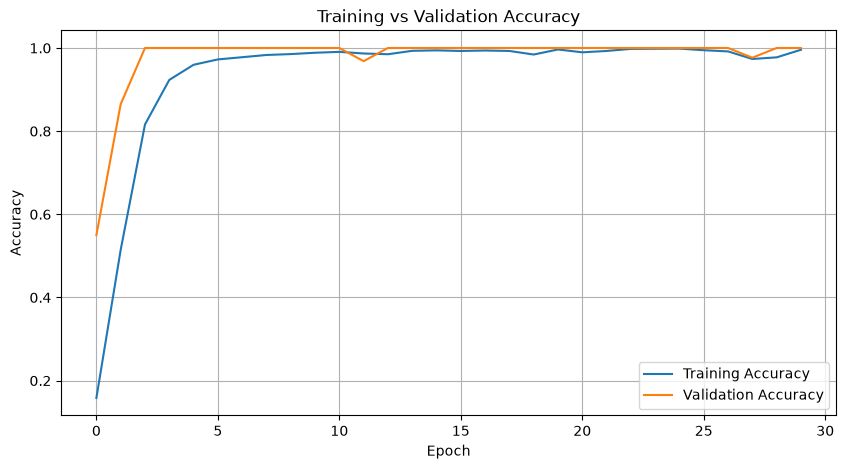

In [17]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [18]:
predicted_class = label_encoder.inverse_transform([15])

print(predicted_class[0])

Real Sociedad


In [19]:
model.save("../model/laliga_cnn_model.keras")

In [20]:
import pickle

In [22]:
with open("../model/label_encoder.pkl", "wb") as file:
    pickle.dump(label_encoder, file)